# ResNet 论文精讲与完整 PyTorch 实现｜arXiv:1512.03385

# Deep Residual Learning for Image Recognition — ResNet 原论文精读 + 完整可执行实现

**论文：** Kaiming He, Xiangyu Zhang, Shaoqing Ren, Jian Sun (2015/2016), [arXiv:1512.03385](https://arxiv.org/pdf/1512.03385) · [CVPR 2016 Open Access](https://openaccess.thecvf.com/content_cvpr_2016/papers/He_Deep_Residual_Learning_CVPR_2016_paper.pdf)

**Colab 运行说明（GPU 自动选择）：** 在 Google Colab 中选择 **Runtime → Change runtime type → T4 GPU（如可用）** 后，依次运行全部 Cell；Notebook 会自动探测 CUDA，缺少 GPU 时改用 CPU。`torch`、`numpy`、`pandas`、`matplotlib` 通常已在 Colab 安装；如环境不同，请先安装缺失依赖。默认不下载 CIFAR/ImageNet、无权重下载、无需挂载 Drive。输出保存在 Colab 临时 `/content/resnet-paper-lab`，重启运行时会丢失；可按文末指引选择性复制工件到 Drive。

**本教程的目标：** 不只看公式，而是动手实现 ImageNet ResNet-18/34/50/101/152、CIFAR 6n+2 家族的零参数 Option A 与投影 Option B 捷径，训练一个真正的小模型、保存/恢复检查点，并用数值断言、`print`、表格和图表交叉检查论文机制。

> **复现实验声明：** 整本 Notebook 可在 CPU、无网络/无下载环境使用内置合成图像完成执行。合成数据曲线 **不是论文 ImageNet/CIFAR-10 结果**。后文另给实际 CIFAR-10 和 ImageNet 的可选数据加载/训练路径，但不自动下载数据，也不声称已复现原论文的精度、规模或 COCO 检测实验。

| 审计来源 | 内容 |
|---|---|
| §3.1–3.2 / 式 (1)(2) | $y = \mathcal F(x,{W_i})+x$；通道变化使用 $W_s x$ |
| Fig. 2 / Fig. 5 | BasicBlock 与 Bottleneck 的 2/3 层残差分支 |
| Table 1 | ImageNet ResNet-18/34/50/101/152 层数、阶段宽度与堆叠次数 |
| §3.4 | BN、Kaiming 初始化、SGD + momentum、weight decay |
| §4.2 / Table 6 | CIFAR-10 的 $6n+2$ 架构，Option A 无参数捷径 |
| Table 3–5 / Fig. 4 | 论文公开的 ImageNet 误差，用于解释，不作为本次实验测量值 |

**范围边界：** 实现分类主干、训练/评估与推理。Faster R-CNN/COCO 多任务系统涉及额外检测框架、数据集和训练规模，不属于本 Notebook 的已复现结果。

## 学习路线与验收清单

1. 明确 degradation problem 与梯度消失的区别；解析 $\mathcal F(x)+x$。
2. 用图形、输出 Shape 和数值梯度验证捷径连接。
3. 从头实现全部五种 ImageNet ResNet，确认参数量、Stage 输出与理论算量。
4. 从头实现 CIFAR 6n+2 ResNet-20/32/56/110，区分 Option A/B。
5. 基于完全本地、可控的数据训练小型模型，得到真实 Loss、验证准确率、混淆矩阵和 Checkpoint。
6. 配置真实 CIFAR-10 与 ImageNet 数据训练入口（**显式开关，默认不运行**）。
7. 保存可追溯工件、原论文报告值对比图和质量断言。

**运行要求：** Python、PyTorch 2.x、NumPy、Matplotlib、Pandas、IPython；可选 torchvision（在第 11 节使用）。无需下载预训练权重或大型数据。

In [1]:
from pathlib import Path
import os, gc, json, math, time, random, sys, platform, hashlib
from contextlib import nullcontext
import torch, numpy as np, matplotlib.pyplot as plt, pandas as pd
from torch import nn
from torch.nn import functional as F
from IPython.display import display
from collections import Counter
IN_COLAB = 'google.colab' in sys.modules or bool(os.environ.get('COLAB_RELEASE_TAG'))
ROOT = Path(os.environ.get('RESNET_WORKDIR', '/content/resnet-paper-lab' if IN_COLAB else str(Path.cwd()))).expanduser().resolve()
ROOT.mkdir(parents=True, exist_ok=True)
SOURCE_URL='https://arxiv.org/pdf/1512.03385'
FIG=ROOT/'figures'; FIG.mkdir(parents=True,exist_ok=True)
ART=ROOT/'artifacts'; ART.mkdir(parents=True,exist_ok=True)
SEED=2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
requested=os.getenv('RESNET_DEVICE','auto').lower()
if requested not in ('auto','cpu','cuda'): raise ValueError('RESNET_DEVICE must be auto|cpu|cuda')
if requested=='cuda' and not torch.cuda.is_available(): raise RuntimeError('CUDA explicitly requested but unavailable')
DEVICE=torch.device('cuda' if (requested=='cuda' or (requested=='auto' and torch.cuda.is_available())) else 'cpu')
# Autocast is optional and applies to toy training only; model inspection stays CPU to avoid GPU OOM.
AMP_ENABLED = DEVICE.type=='cuda' and os.environ.get('RESNET_AMP','1')=='1'
AMP_DTYPE = torch.bfloat16 if (AMP_ENABLED and torch.cuda.is_bf16_supported()) else torch.float16
def autocast_context():
    return torch.autocast(device_type='cuda',dtype=AMP_DTYPE) if AMP_ENABLED else nullcontext()
def make_grad_scaler():
    return torch.amp.GradScaler('cuda',enabled=(AMP_ENABLED and AMP_DTYPE==torch.float16)) if AMP_ENABLED else None
torch.set_num_threads(min(2,torch.get_num_threads()))
def show_fig(fig,filename):
    path=FIG/filename; fig.savefig(path,dpi=135,bbox_inches='tight')
    display(fig);plt.close(fig)
    print('Figure:',path.name,'bytes=',path.stat().st_size)
print('Python:',sys.version.split()[0], '| Torch:',torch.__version__, '| NumPy:',np.__version__)
print('Execution device:', str(DEVICE), '| AMP:', AMP_ENABLED, '| dtype:',str(AMP_DTYPE) if AMP_ENABLED else 'fp32')
print('CPU threads:',torch.get_num_threads(), '| CUDA available:',torch.cuda.is_available(),'| root:',ROOT)
if DEVICE.type=='cuda':
    print('GPU:',torch.cuda.get_device_name(0),'| memory GiB:',round(torch.cuda.get_device_properties(0).total_memory/2**30,2))
else:
    print('CPU fallback active. Colab: Runtime > Change runtime type > GPU if accelerator is available.')
print('No external dataset or checkpoint will be downloaded in default execution.')
assert torch.__version__ and len(str(ROOT))>0

Python: 3.13.5 | Torch: 2.10.0+cpu | NumPy: 2.3.5
Execution device: cpu | AMP: False | dtype: fp32
CPU threads: 2 | CUDA available: False | root: /mnt/notebook-builder/tutorials/resnet/outputs
CPU fallback active. Colab: Runtime > Change runtime type > GPU if accelerator is available.
No external dataset or checkpoint will be downloaded in default execution.


## 1. 为什么深层 Plain Net 不一定训练得更好？（论文 Fig. 1/4）

**退化（degradation）** 指更深网络即使理论表达空间包含浅网络，也可能在优化中得到**更高训练误差**。这不同于“训练集好、测试集差”的过拟合，也不能简单等同于梯度消失。论文在 BN 条件下观察到更深 plain 网络训练误差更高。

直觉：如果一个额外网络层要实现 $H(x)=x$，Plain 分支必须学习恒等映射；ResNet 写成 $H(x)=x+F(x)$，只需让 $F(x)\approx 0$。

Identity target MSE | plain zero mapping: 1.3512
Identity target MSE | residual zero branch: 0.0


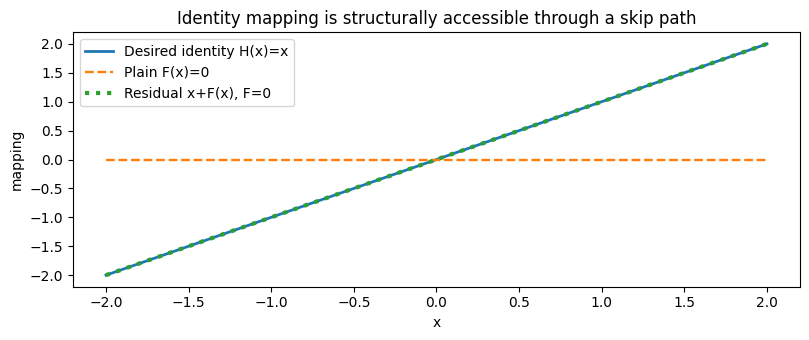

Figure: 01_identity_mapping.png bytes= 53975


In [2]:
# A deliberately controlled algebraic illustration, not a reproduction of Fig.4 accuracy curves.
x=torch.linspace(-2,2,150)
target=x+0.2*torch.sin(3*x)
plain_identity=torch.zeros_like(x)   # a zero-initialized plain function
residual_identity=x+torch.zeros_like(x)
print('Identity target MSE | plain zero mapping:',round(float(F.mse_loss(plain_identity,x)),4))
print('Identity target MSE | residual zero branch:',round(float(F.mse_loss(residual_identity,x)),4))
fig,ax=plt.subplots(figsize=(8.2,3.5))
ax.plot(x, x, label='Desired identity H(x)=x',lw=2)
ax.plot(x,plain_identity,'--',label='Plain F(x)=0',lw=1.7)
ax.plot(x,residual_identity,':',label='Residual x+F(x), F=0',lw=3)
ax.set_xlabel('x');ax.set_ylabel('mapping');ax.set_title('Identity mapping is structurally accessible through a skip path');ax.legend();fig.tight_layout()
show_fig(fig,'01_identity_mapping.png')
assert torch.allclose(residual_identity,x)

## 2. 残差加法的 Jacobian 与梯度路径

对于 $y=x+F(x)$，链式法则给出 $\partial y/\partial x=I+\partial F/\partial x$。这不是声称梯度永远不消失：原论文 Block 的加法**之后仍有 ReLU**、BN 等操作，优化效果依赖数据与初始化；下面专门用不含后置 ReLU 的**代数玩具示例**检验恒等梯度项。

residual chain depth: 1 | grad mean: 1.0 | min/max: 1.0 1.0
residual chain depth: 4 | grad mean: 1.0 | min/max: 1.0 1.0
residual chain depth: 16 | grad mean: 1.0 | min/max: 1.0 1.0
residual chain depth: 64 | grad mean: 1.0 | min/max: 1.0 1.0
plain 0.5^16 chain gradient: 1.52587890625e-05


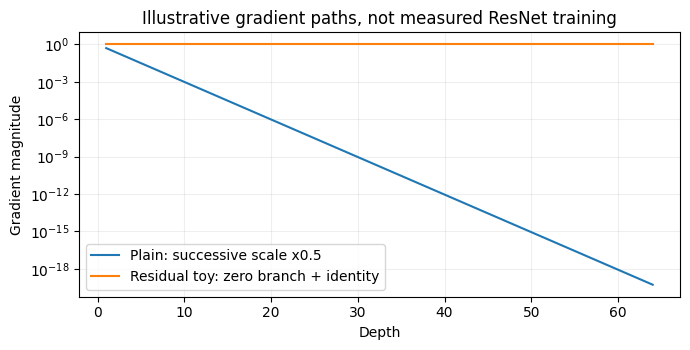

Figure: 02_toy_gradient_paths.png bytes= 54436


In [3]:
for depth in (1,4,16,64):
    x0=torch.randn(7,requires_grad=True)
    z=x0
    for _ in range(depth): z=z+0.0*z  # F(x)=0 for every block
    g=torch.autograd.grad(z.sum(),x0)[0]
    print('residual chain depth:',depth,'| grad mean:',round(g.mean().item(),6),'| min/max:',round(g.min().item(),6),round(g.max().item(),6))
    assert torch.equal(g,torch.ones_like(x0))
x0=torch.randn(7,requires_grad=True)
z=x0
for _ in range(16):z=0.5*z
grad_plain=torch.autograd.grad(z.sum(),x0)[0]
print('plain 0.5^16 chain gradient:',grad_plain[0].item())
fig,ax=plt.subplots(figsize=(7,3.6))
dep=np.arange(1,65)
ax.semilogy(dep,np.power(.5,dep),label='Plain: successive scale x0.5')
ax.semilogy(dep,np.ones_like(dep),label='Residual toy: zero branch + identity')
ax.set_xlabel('Depth');ax.set_ylabel('Gradient magnitude');ax.legend();ax.grid(alpha=.2)
ax.set_title('Illustrative gradient paths, not measured ResNet training');fig.tight_layout()
show_fig(fig,'02_toy_gradient_paths.png')

## 3. BasicBlock、Bottleneck 与 Shortcut（论文 Fig. 2 / Fig. 5）

**BasicBlock（ResNet-18/34）：** $3\times3$ Conv–BN–ReLU → $3\times3$ Conv–BN → 与 shortcut 相加 → ReLU。

**Bottleneck（ResNet-50/101/152）：** $1\times1$ 降维 → $3\times3$ 空间卷积 → $1\times1$ 升维（扩张系数 4） → 加法 → ReLU。

当输入输出 Shape 相同时捷径是严格 Identity；当通道或空间尺寸变化时采用带 stride 的 $1\times1$ Projection + BN（ImageNet 版本采用论文选项 B）。

注意实现差异：**本教程的 Bottleneck stride 放在第一个 $1\times1$ Conv 上**以匹配早期 ResNet-v1；torchvision 的常见 ResNet-v1.5 将 stride 放在中间的 $3\times3$ Conv 上。两者 Tensor Shape 一样，但运算位置不同，不能混同。

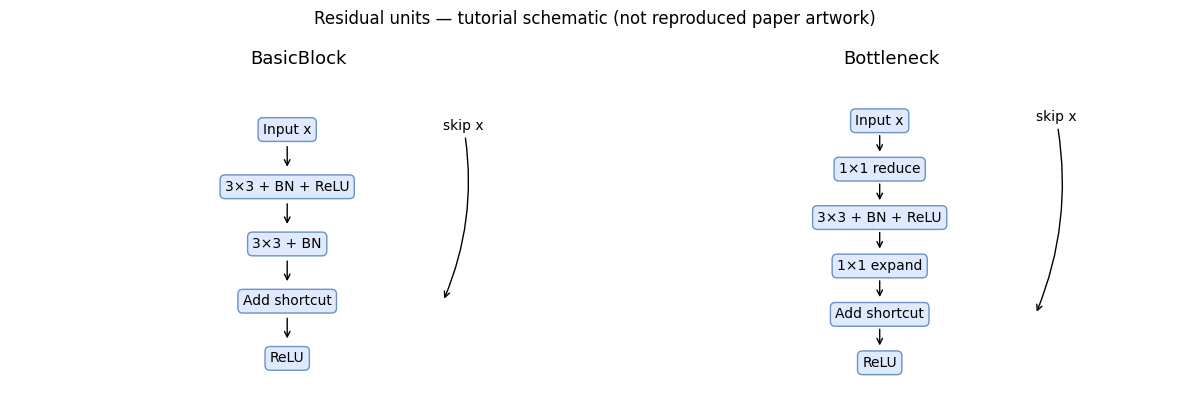

Figure: 03_residual_blocks.png bytes= 59829


In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,items,title in [
    (axes[0],['Input x','3×3 + BN + ReLU','3×3 + BN','Add shortcut','ReLU'],'BasicBlock'),
    (axes[1],['Input x','1×1 reduce','3×3 + BN + ReLU','1×1 expand','Add shortcut','ReLU'],'Bottleneck')]:
    ax.set_xlim(0,10);ax.set_ylim(-.5,len(items));ax.axis('off');ax.set_title(title,fontsize=13)
    for i,item in enumerate(items):
        yy=len(items)-i-1
        ax.text(4.8,yy,item,ha='center',va='center',bbox={'boxstyle':'round,pad=.35','facecolor':'#dfeaff','edgecolor':'#6b91c6'})
        if i:ax.annotate('',xy=(4.8,yy+.3),xytext=(4.8,yy+.75),arrowprops={'arrowstyle':'->'})
    ax.annotate('skip x',xy=(7.5,1 if title=='BasicBlock' else 1.0),xytext=(7.5,len(items)-1),arrowprops={'arrowstyle':'->','connectionstyle':'arc3,rad=-.15'},ha='left')
fig.suptitle('Residual units — tutorial schematic (not reproduced paper artwork)');fig.tight_layout()
show_fig(fig,'03_residual_blocks.png')

## 4. 完整网络源码：从头实现（可直接在 Notebook 重跑）

下方代码是**全部模型实现**，不是伪代码、依赖外部项目的空壳或只实现 forward 的片段。包括 Kaiming 初始化、BN、所有 ResNet 深度、CIFAR Option A/B、全局平均池化、参数量及 Top-k 评价。实现没有加载原论文模型权重；新初始化模型的 logits 不能解释为 ImageNet 分类性能。

In [5]:
"""ResNet-v1 reference architecture for the executable arXiv:1512.03385 tutorial.

Original-paper behavior: post-add ReLU and bottleneck stride in the first 1x1 conv.
Supports ImageNet 18/34/50/101/152 and CIFAR-10 6n+2, with shortcut A/B.
No trained weights, downloads, or pretrained-performance claims.
"""
from __future__ import annotations
import torch
from torch import nn
from torch.nn import functional as F


def conv3x3(inp:int, out:int, stride:int=1):
    return nn.Conv2d(inp, out, kernel_size=3, stride=stride, padding=1, bias=False)


def conv1x1(inp:int, out:int, stride:int=1):
    return nn.Conv2d(inp, out, kernel_size=1, stride=stride, bias=False)


class BasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes:int, planes:int, stride:int=1, downsample=None):
        super().__init__()
        self.conv1=conv3x3(inplanes,planes,stride)
        self.bn1=nn.BatchNorm2d(planes)
        self.relu=nn.ReLU(inplace=True)
        self.conv2=conv3x3(planes,planes)
        self.bn2=nn.BatchNorm2d(planes)
        self.downsample=downsample
    def forward(self,x):
        identity=x
        out=self.relu(self.bn1(self.conv1(x)))
        out=self.bn2(self.conv2(out))
        if self.downsample is not None:identity=self.downsample(x)
        out=out+identity
        return self.relu(out)


class Bottleneck(nn.Module):
    expansion = 4
    def __init__(self,inplanes:int,planes:int,stride:int=1,downsample=None):
        super().__init__()
        # Original ResNet-v1 stride is on the first 1x1 (not torchvision's v1.5 3x3).
        self.conv1=conv1x1(inplanes,planes,stride)
        self.bn1=nn.BatchNorm2d(planes)
        self.conv2=conv3x3(planes,planes)
        self.bn2=nn.BatchNorm2d(planes)
        self.conv3=conv1x1(planes,planes*self.expansion)
        self.bn3=nn.BatchNorm2d(planes*self.expansion)
        self.relu=nn.ReLU(inplace=True)
        self.downsample=downsample
    def forward(self,x):
        identity=x
        out=self.relu(self.bn1(self.conv1(x)))
        out=self.relu(self.bn2(self.conv2(out)))
        out=self.bn3(self.conv3(out))
        if self.downsample is not None:identity=self.downsample(x)
        return self.relu(out+identity)


class ImageNetResNet(nn.Module):
    def __init__(self,block,layers, num_classes:int=1000, zero_init_residual:bool=False):
        super().__init__()
        self.inplanes=64
        self.conv1=nn.Conv2d(3,64,7,stride=2,padding=3,bias=False)
        self.bn1=nn.BatchNorm2d(64)
        self.relu=nn.ReLU(inplace=True)
        self.maxpool=nn.MaxPool2d(3,stride=2,padding=1)
        self.layer1=self._make_layer(block,64,layers[0],stride=1)
        self.layer2=self._make_layer(block,128,layers[1],stride=2)
        self.layer3=self._make_layer(block,256,layers[2],stride=2)
        self.layer4=self._make_layer(block,512,layers[3],stride=2)
        self.avgpool=nn.AdaptiveAvgPool2d((1,1))
        self.fc=nn.Linear(512*block.expansion,num_classes)
        for m in self.modules():
            if isinstance(m,nn.Conv2d):nn.init.kaiming_normal_(m.weight,mode='fan_out',nonlinearity='relu')
            elif isinstance(m,nn.BatchNorm2d):
                nn.init.ones_(m.weight);nn.init.zeros_(m.bias)
        if zero_init_residual:
            # Optional modern training enhancement, NOT claimed to be original 2015 recipe.
            for m in self.modules():
                if isinstance(m,Bottleneck):nn.init.zeros_(m.bn3.weight)
                elif isinstance(m,BasicBlock):nn.init.zeros_(m.bn2.weight)
    def _make_layer(self,block,planes,blocks,stride=1):
        outplanes=planes*block.expansion
        downsample=None
        if stride!=1 or self.inplanes!=outplanes:
            downsample=nn.Sequential(conv1x1(self.inplanes,outplanes,stride),nn.BatchNorm2d(outplanes))
        seq=[block(self.inplanes,planes,stride,downsample)]
        self.inplanes=outplanes
        seq.extend(block(self.inplanes,planes) for _ in range(1,blocks))
        return nn.Sequential(*seq)
    def forward_features(self,x):
        x=self.maxpool(self.relu(self.bn1(self.conv1(x))))
        for layer in [self.layer1,self.layer2,self.layer3,self.layer4]:x=layer(x)
        return x
    def forward(self,x):
        x=self.forward_features(x)
        return self.fc(torch.flatten(self.avgpool(x),1))

RESNET_SPECS = {'18':(BasicBlock,[2,2,2,2]),'34':(BasicBlock,[3,4,6,3]),
                '50':(Bottleneck,[3,4,6,3]),'101':(Bottleneck,[3,4,23,3]),
                '152':(Bottleneck,[3,8,36,3])}

def imagenet_resnet(depth:int=18,num_classes:int=1000,**kwargs):
    if str(depth) not in RESNET_SPECS:raise ValueError(f'Unsupported depth {depth}')
    block, layers=RESNET_SPECS[str(depth)]
    return ImageNetResNet(block,layers,num_classes=num_classes,**kwargs)


class OptionAShortcut(nn.Module):
    """Original CIFAR Option A: stride by spatial subsampling and zero-pad channels."""
    def __init__(self,inplanes:int,outplanes:int,stride:int):
        super().__init__()
        self.inplanes,self.outplanes,self.stride=inplanes,outplanes,stride
        if outplanes<inplanes:raise ValueError('Option A shortcut does not reduce channels')
    def forward(self,x):
        if self.stride!=1:x=x[:,:,::self.stride,::self.stride]
        delta=self.outplanes-x.shape[1]
        if delta:
            before=delta//2
            # Padding the channel dimension by zero tensors. F.pad's channel axis is -3.
            x=F.pad(x,(0,0,0,0,before,delta-before))
        return x


class CIFARBasicBlock(nn.Module):
    expansion=1
    def __init__(self,inplanes,planes,stride=1,shortcut='A'):
        super().__init__()
        self.conv1=conv3x3(inplanes,planes,stride)
        self.bn1=nn.BatchNorm2d(planes)
        self.relu=nn.ReLU(inplace=True)
        self.conv2=conv3x3(planes,planes)
        self.bn2=nn.BatchNorm2d(planes)
        if stride==1 and inplanes==planes:self.shortcut=nn.Identity()
        elif shortcut=='A':self.shortcut=OptionAShortcut(inplanes,planes,stride)
        elif shortcut=='B':self.shortcut=nn.Sequential(conv1x1(inplanes,planes,stride),nn.BatchNorm2d(planes))
        else:raise ValueError('shortcut must be A or B')
    def forward(self,x):
        y=self.relu(self.bn1(self.conv1(x)))
        y=self.bn2(self.conv2(y))
        return self.relu(y+self.shortcut(x))


class CIFARResNet(nn.Module):
    """Paper CIFAR 6n+2: 3x3 stem and three stage widths 16/32/64.
    base_width=16 reproduces nominal paper network; smaller width is educational.
    """
    def __init__(self,n:int=3,num_classes:int=10,shortcut='A',base_width:int=16):
        super().__init__()
        if n<1:raise ValueError('n must be positive')
        self.n=n;self.depth=6*n+2
        self.stem=nn.Sequential(conv3x3(3,base_width),nn.BatchNorm2d(base_width),nn.ReLU(inplace=True))
        self.stages=nn.Sequential(*self._make_stages(n,shortcut,base_width))
        self.pool=nn.AdaptiveAvgPool2d((1,1))
        self.fc=nn.Linear(base_width*4,num_classes)
        for m in self.modules():
            if isinstance(m,nn.Conv2d):nn.init.kaiming_normal_(m.weight,mode='fan_out',nonlinearity='relu')
            elif isinstance(m,nn.BatchNorm2d):nn.init.ones_(m.weight);nn.init.zeros_(m.bias)
    def _make_stages(self,n,shortcut,base_width):
        previous=base_width; stages=[]
        for stage_idx in range(3):
            width=base_width*2**stage_idx
            units=[]
            for block_idx in range(n):
                stride=2 if stage_idx>0 and block_idx==0 else 1
                units.append(CIFARBasicBlock(previous,width,stride,shortcut))
                previous=width
            stages.append(nn.Sequential(*units))
        return stages
    def forward(self,x):
        y=self.stages(self.stem(x))
        return self.fc(torch.flatten(self.pool(y),1))


def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def topk_accuracy(logits, targets, k:int=1):
    if not 1<=k<=logits.shape[1]:raise ValueError('Invalid k')
    best=logits.topk(k,dim=1).indices
    return (best==targets[:,None]).any(dim=1).float().mean().item()

In [6]:
print('Source classes:', [x.__name__ for x in (BasicBlock,Bottleneck,ImageNetResNet,OptionAShortcut,CIFARBasicBlock,CIFARResNet)])
print('ImageNet model configurations:',{k:[x.__name__,v] for k,(x,v) in RESNET_SPECS.items()})
assert RESNET_SPECS['101'][1]==[3,4,23,3]
assert RESNET_SPECS['152'][1]==[3,8,36,3]

Source classes: ['BasicBlock', 'Bottleneck', 'ImageNetResNet', 'OptionAShortcut', 'CIFARBasicBlock', 'CIFARResNet']
ImageNet model configurations: {'18': ['BasicBlock', [2, 2, 2, 2]], '34': ['BasicBlock', [3, 4, 6, 3]], '50': ['Bottleneck', [3, 4, 6, 3]], '101': ['Bottleneck', [3, 4, 23, 3]], '152': ['Bottleneck', [3, 8, 36, 3]]}


## 5. ResNet-18/34/50/101/152：参数审计与 Stage 划分（论文 Table 1）

Table 1 给出的 Block 数分别为 `[2,2,2,2]` / `[3,4,6,3]` / `[3,4,6,3]` / `[3,4,23,3]` / `[3,8,36,3]`；从头实现 5 个模型并检查参数量和分类头尺寸。对 101/152 只做构造/静态审计，不在 CPU 上执行全尺寸 ImageNet 前向训练。

,depth,block,stage_repeats,parameters,parameters_M,last_channels,conv_modules
0,18,BasicBlock,"[2, 2, 2, 2]",11689512,11.69,512,20
1,34,BasicBlock,"[3, 4, 6, 3]",21797672,21.80,512,36
2,50,Bottleneck,"[3, 4, 6, 3]",25557032,25.56,2048,53
3,101,Bottleneck,"[3, 4, 23, 3]",44549160,44.55,2048,104
4,152,Bottleneck,"[3, 8, 36, 3]",60192808,60.19,2048,155


Parameter vector: [11.69, 21.8, 25.56, 44.55, 60.19]


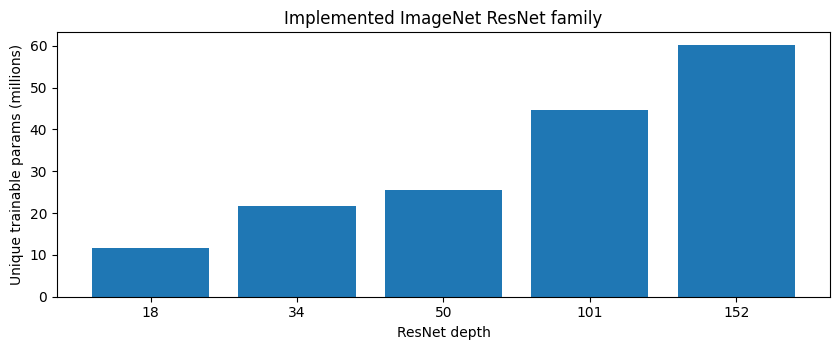

Figure: 04_parameter_counts.png bytes= 28365


In [7]:
architecture_rows=[]
for depth in (18,34,50,101,152):
    m=imagenet_resnet(depth)
    unit,stacks=RESNET_SPECS[str(depth)]
    params=parameter_count(m)
    conv_count=sum(isinstance(layer,nn.Conv2d) for layer in m.modules())
    row={'depth':depth,'block':unit.__name__,'stage_repeats':str(stacks),'parameters':params,'parameters_M':round(params/1e6,2),
         'last_channels':m.fc.in_features,'conv_modules':conv_count}
    architecture_rows.append(row)
    assert depth==1+len(stacks)*0+sum(stacks)*(2 if unit is BasicBlock else 3)+1
    assert params>1_000_000
    del m
gc.collect()
architecture=pd.DataFrame(architecture_rows);display(architecture)
print('Parameter vector:',architecture['parameters_M'].tolist())
fig,ax=plt.subplots(figsize=(8.5,3.6));ax.bar(architecture['depth'].astype(str),architecture['parameters_M'])
ax.set_xlabel('ResNet depth');ax.set_ylabel('Unique trainable params (millions)');ax.set_title('Implemented ImageNet ResNet family');fig.tight_layout()
show_fig(fig,'04_parameter_counts.png')

## 6. 用 Hooks 追踪真实特征 Shape、降采样和投影

对标准 ImageNet 输入 `224×224`，期望特征图序列：stem 输出 `112×112`，maxpool 后 `56×56`，四个阶段 `56/28/14/7`。本实验用更小 `64×64` 输入以快速执行，比例关系不变。

ResNet 18 Stage shapes: {'conv1': (1, 64, 32, 32), 'maxpool': (1, 64, 16, 16), 'layer1': (1, 64, 16, 16), 'layer2': (1, 128, 8, 8), 'layer3': (1, 256, 4, 4), 'layer4': (1, 512, 2, 2), 'avgpool': (1, 512, 1, 1), 'fc': (1, 1000)}
Predicted (untrained) top-1 class index: 679 | logits range: -3.162809371948242 4.107991695404053


ResNet 50 Stage shapes: {'conv1': (1, 64, 32, 32), 'maxpool': (1, 64, 16, 16), 'layer1': (1, 256, 16, 16), 'layer2': (1, 512, 8, 8), 'layer3': (1, 1024, 4, 4), 'layer4': (1, 2048, 2, 2), 'avgpool': (1, 2048, 1, 1), 'fc': (1, 1000)}
Predicted (untrained) top-1 class index: 118 | logits range: -30.495344161987305 32.91182327270508


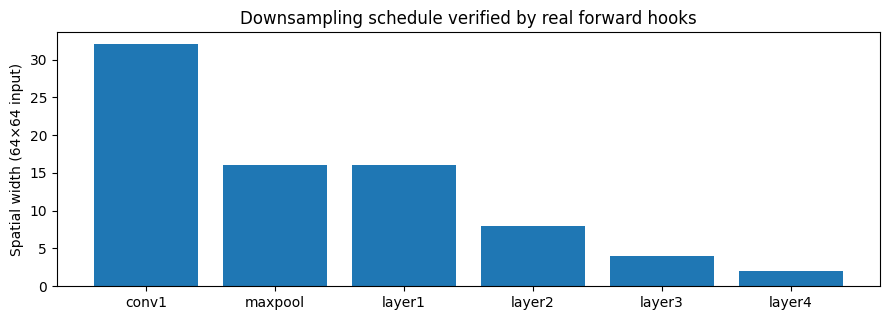

Figure: 05_spatial_resolution.png bytes= 30530


In [8]:
def stage_shapes(model,image):
    recorded={};handles=[]
    for name in ['conv1','maxpool','layer1','layer2','layer3','layer4','avgpool','fc']:
        mod=getattr(model,name)
        handles.append(mod.register_forward_hook(lambda _,inputs,output,name=name:recorded.__setitem__(name,tuple(output.shape))))
    try:
        with torch.inference_mode():y=model(image)
    finally:
        for h in handles:h.remove()
    return y,recorded
for depth in (18,50):
    m=imagenet_resnet(depth).eval()
    y,shapes=stage_shapes(m,torch.randn(1,3,64,64))
    print('ResNet',depth,'Stage shapes:',shapes)
    print('Predicted (untrained) top-1 class index:',y.argmax(-1).item(),'| logits range:',float(y.min()),float(y.max()))
    assert shapes['layer1'][-2:]==(16,16) and shapes['layer4'][-2:]==(2,2)
    assert y.shape==(1,1000)
    del m
fig,ax=plt.subplots(figsize=(9,3.3))
names=['conv1','maxpool','layer1','layer2','layer3','layer4']
ax.bar(names,[shapes[x][-1] for x in names]);ax.set_ylabel('Spatial width (64×64 input)');ax.set_title('Downsampling schedule verified by real forward hooks');fig.tight_layout()
show_fig(fig,'05_spatial_resolution.png')

## 7. 捷径选项 A/B 的实现与梯度检查

- **ImageNet：** 通道数或空间尺寸改变 → `Conv1×1(stride) + BN`，输出与 $F(x)$ 逐元素相加。
- **CIFAR Option A：** 空间下采样 + 通道零填充，不引入可训练参数；本教程的默认 CIFAR 路线。
- **CIFAR Option B：** 在通道变化处使用可学习 `1×1` Projection。

下面直接测试 `16→32` 通道下采样、零填充是否产生正确 Shape，同时检查残差分支参数梯度。

In [9]:
t=torch.randn(2,16,32,32,requires_grad=True)
a=OptionAShortcut(16,32,2)(t)
print('Option A input:',tuple(t.shape),'output:',tuple(a.shape))
assert a.shape==(2,32,16,16)
assert torch.all(a[:,:8]==0) and torch.all(a[:,24:]==0)
assert torch.allclose(a[:,8:24],t[:,:,::2,::2])
b=CIFARBasicBlock(16,32,stride=2,shortcut='B')
b.eval();out=b(t)
print('Option B output:',tuple(out.shape),'parameters:',parameter_count(b))
out.square().mean().backward()
print('Gradient mean magnitude | input:',t.grad.abs().mean().item(),'| first conv:',b.conv1.weight.grad.abs().mean().item())
assert t.grad.abs().sum().item()>0 and b.conv1.weight.grad.abs().sum().item()>0

Option A input: (2, 16, 32, 32) output: (2, 32, 16, 16)
Option B output: (2, 32, 16, 16) parameters: 14528
Gradient mean magnitude | input: 1.7190061043947935e-05 | first conv: 0.000483204610645771


## 8. CIFAR-10 架构：准确构建 6n+2 层（论文 §4.2、Table 6）

论文 CIFAR 网络使用 3×3 Stem，然后三组特征尺寸 32→16→8，每组宽度 16→32→64，每组有 n 个 BasicBlock，总深度 $6n+2$。示例 n=3/5/9/18 对应 ResNet-20/32/56/110。**没有 7×7 Stem 或 ImageNet MaxPool**。

,n,depth,parameters,parameters_M
0,3,20,269722,0.270
1,5,32,464154,0.464
2,9,56,853018,0.853
3,18,110,1727962,1.728


CIFAR-20 logits: (2, 10) params: 269722


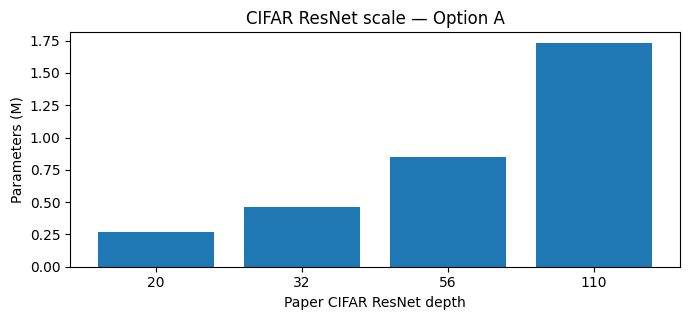

Figure: 06_cifar_parameters.png bytes= 28039


In [10]:
cifar_rows=[]
for n in (3,5,9,18):
    m=CIFARResNet(n,shortcut='A')
    row={'n':n,'depth':m.depth,'parameters':parameter_count(m),'parameters_M':round(parameter_count(m)/1e6,3)}
    cifar_rows.append(row)
    assert m.depth==6*n+2
    del m
table=pd.DataFrame(cifar_rows);display(table)
small=CIFARResNet(n=3,shortcut='A').eval()
with torch.inference_mode():y=small(torch.randn(2,3,32,32))
print('CIFAR-20 logits:',tuple(y.shape),'params:',parameter_count(small))
assert y.shape==(2,10)
fig,ax=plt.subplots(figsize=(7,3.3));ax.bar(table['depth'].astype(str),table['parameters_M'])
ax.set_xlabel('Paper CIFAR ResNet depth');ax.set_ylabel('Parameters (M)')
ax.set_title('CIFAR ResNet scale — Option A');fig.tight_layout()
show_fig(fig,'06_cifar_parameters.png')
del small

## 9. 推导原论文的算量 vs 真实测量的 MACs

论文 Table 1 报告 ResNet-18/34/50/101/152 大致 1.8/3.6/3.8/7.6/11.3 **billion FLOPs**。实践中很多深度学习框架把一次乘加计为一个 MAC，有些资料定义 FLOPs 为 $2\times$ MAC。这里通过 forward hooks 统计卷积和线性层的 **MACs**，忽略 BN、ReLU、Pool 与逐元素加法，因此不要混为精确 FLOPs。

ResNet 18 estimated conv+linear MACs: 1.814 G, paper approx FLOPs: 1.8 G


ResNet 50 estimated conv+linear MACs: 3.858 G, paper approx FLOPs: 3.8 G


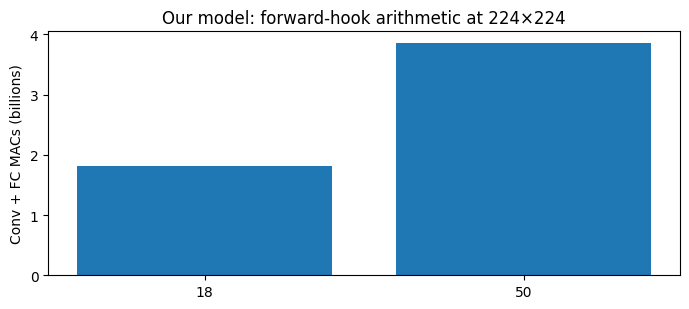

Figure: 07_measured_macs.png bytes= 20364


In [11]:
def conv_linear_macs(net,shape=(1,3,224,224)):
    total=[0];handles=[]
    def hook(mod,inputs,out):
        if isinstance(mod,nn.Conv2d):
            batch,cout,h,w=out.shape
            mac=batch*cout*h*w*(mod.in_channels//mod.groups)*mod.kernel_size[0]*mod.kernel_size[1]
        elif isinstance(mod,nn.Linear):mac=out.numel()*mod.in_features
        else:return
        total[0]+=int(mac)
    for layer in net.modules():
        if isinstance(layer,(nn.Conv2d,nn.Linear)):handles.append(layer.register_forward_hook(hook))
    try:
        with torch.inference_mode():net.eval()(torch.zeros(shape))
    finally:
        for h in handles:h.remove()
    return total[0]
measured=[]
for depth in (18,50):
    net=imagenet_resnet(depth)
    macs=conv_linear_macs(net)
    measured.append((depth,macs/1e9))
    print('ResNet',depth,'estimated conv+linear MACs:',round(macs/1e9,3),'G, paper approx FLOPs:',1.8 if depth==18 else 3.8,'G')
    del net
fig,ax=plt.subplots(figsize=(7,3.2))
ax.bar([str(p[0]) for p in measured],[p[1] for p in measured]);ax.set_ylabel('Conv + FC MACs (billions)')
ax.set_title('Our model: forward-hook arithmetic at 224×224');fig.tight_layout()
show_fig(fig,'07_measured_macs.png')

## 10. 合成图像分类：无需下载的独立训练数据

为了真实验证 `forward → loss → backward → optimizer → validation`，构造三个可辨的 32×32 图案类别：竖条纹、横条纹、圆形。**训练集和验证集由独立 RNG 产生**，不重复使用训练样本；这只用于检查训练管线，不是 CIFAR-10 或 ImageNet 的性能估计。

Synthetic train: (144, 3, 32, 32) validation: (60, 3, 32, 32)
Train counts: [48, 48, 48] Val counts: [20, 20, 20]


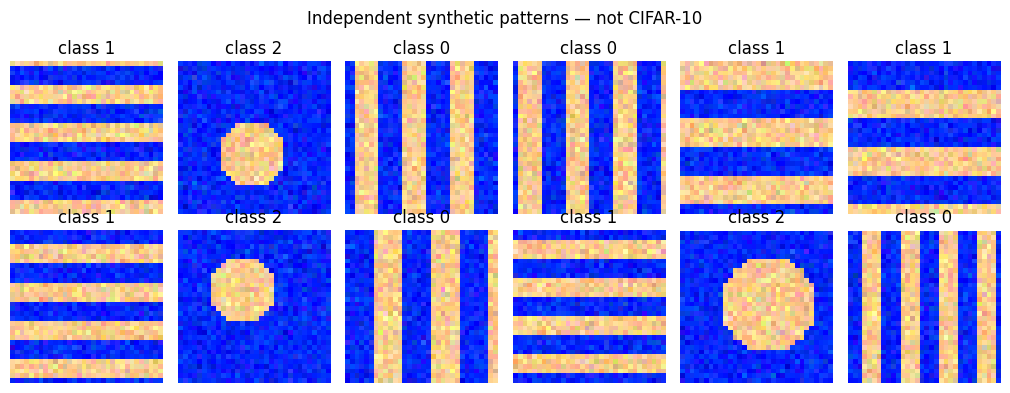

Figure: 08_synthetic_images.png bytes= 76615


In [12]:
def make_shapes(n,seed,side=32):
    rng=np.random.default_rng(seed)
    xx,yy=np.meshgrid(np.arange(side),np.arange(side),indexing='xy')
    xs=np.empty((n,3,side,side),dtype=np.float32);ys=np.empty(n,dtype=np.int64)
    for i in range(n):
        cls=i%3
        phase=int(rng.integers(0,8));freq=int(rng.integers(4,7))
        if cls==0:pattern=((xx+phase)//freq)%2
        elif cls==1:pattern=((yy+phase)//freq)%2
        else:
            cx,cy=rng.integers(12,20,size=2);radius=rng.integers(7,11)
            pattern=((xx-cx)**2+(yy-cy)**2<radius**2).astype(np.float32)
        im=np.stack([pattern,pattern*.65+.15,1-pattern*.45],axis=0)
        xs[i]=np.clip(im+rng.normal(0,.08,size=im.shape),0,1)
        ys[i]=cls
    order=rng.permutation(n)
    return torch.from_numpy(xs[order].copy()),torch.from_numpy(ys[order].copy())
Xtr,Ytr=make_shapes(144,1234);Xva,Yva=make_shapes(60,5678)
print('Synthetic train:',tuple(Xtr.shape),'validation:',tuple(Xva.shape))
print('Train counts:',torch.bincount(Ytr).tolist(),'Val counts:',torch.bincount(Yva).tolist())
fig,axes=plt.subplots(2,6,figsize=(10.2,4.0))
for ax,i in zip(axes.flat,range(12)):
    ax.imshow(Xtr[i].permute(1,2,0).numpy());ax.set_title(f'class {Ytr[i].item()}');ax.axis('off')
fig.suptitle('Independent synthetic patterns — not CIFAR-10');fig.tight_layout()
show_fig(fig,'08_synthetic_images.png')
assert Xtr.shape==(144,3,32,32) and not torch.equal(Xtr[:10],Xva[:10])

## 11. 端到端自动设备训练：GPU（若可用）/CPU（真实优化）

使用 **CIFAR-family 缩窄版** `n=1, base_width=8, num_classes=3` 快速验证端到端训练。正式论文 CIFAR 模型宽度是 16，本节为了快速演示而缩窄，不声称其为 ResNet-20 论文配置。CUDA 可用时自动迁移模型、数据及评估到 GPU，并可启用 bfloat16/float16 autocast（float16 配合 GradScaler）；否则使用 CPU float32。

我们记录每一步训练 Loss，并每隔固定步数评估保留集。只用 `torch.save(state_dict)` 保存权重，不加载任意不可信 Pickle。运行结束之后会重载并验证输出一致。

Toy training tensors: cpu | model: cpu
step=01  train_loss=1.2206  val_loss=1.1209  val_accuracy=33.3%  grad_norm=2.110
step=04  train_loss=0.8263  val_loss=0.9482  val_accuracy=70.0%  grad_norm=1.731
step=08  train_loss=0.1193  val_loss=0.3338  val_accuracy=100.0%  grad_norm=0.492


step=12  train_loss=0.0178  val_loss=0.6781  val_accuracy=65.0%  grad_norm=0.191
step=16  train_loss=0.0202  val_loss=0.2327  val_accuracy=88.3%  grad_norm=0.291
step=20  train_loss=0.0029  val_loss=0.2920  val_accuracy=83.3%  grad_norm=0.081
step=24  train_loss=0.0005  val_loss=0.2411  val_accuracy=85.0%  grad_norm=0.005
Elapsed (s): 0.34 params: 18987


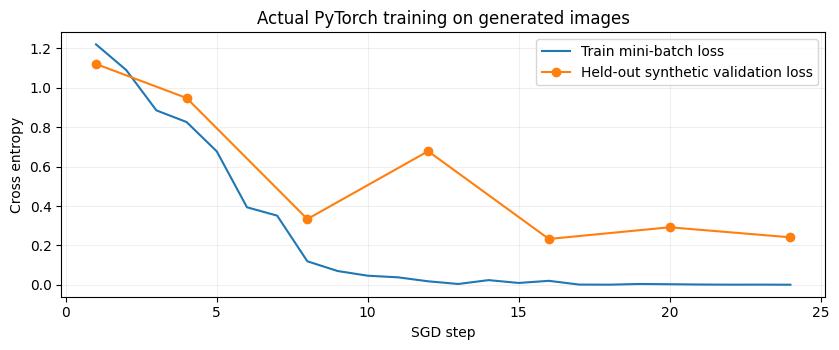

Figure: 09_real_training_loss.png bytes= 57448


In [13]:
torch.manual_seed(SEED)
toy=CIFARResNet(n=1,num_classes=3,shortcut='A',base_width=8).to(DEVICE)
opt=torch.optim.SGD(toy.parameters(),lr=0.10,momentum=.9,weight_decay=1e-4)
criterion=nn.CrossEntropyLoss()
batch_size=18;steps=24
train_curve=[];val_curve=[];val_steps=[]
gen=torch.Generator().manual_seed(7788)
scaler=make_grad_scaler()
train_data=Xtr.to(DEVICE); train_labels=Ytr.to(DEVICE)
val_data=Xva.to(DEVICE); val_labels=Yva.to(DEVICE)
print('Toy training tensors:',str(train_data.device),'| model:',str(next(toy.parameters()).device))
assert next(toy.parameters()).device == train_data.device == val_data.device
tic=time.monotonic()
for step in range(steps):
    toy.train()
    ix=torch.randint(0,len(Xtr),(batch_size,),generator=gen)
    opt.zero_grad(set_to_none=True)
    with autocast_context():
        scores=toy(train_data[ix]);loss=criterion(scores,train_labels[ix])
    if scaler is not None:
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
    else:loss.backward()
    grad_norm=torch.nn.utils.clip_grad_norm_(toy.parameters(),max_norm=10.)
    if scaler is not None:
        scaler.step(opt);scaler.update()
    else:opt.step()
    train_curve.append(float(loss.detach()))
    if step==0 or (step+1)%4==0:
        toy.eval()
        with torch.inference_mode():
            with autocast_context():
                val_scores=toy(val_data)
                vloss=criterion(val_scores,val_labels).item()
            vacc=topk_accuracy(val_scores,val_labels,1)
        val_curve.append(vloss);val_steps.append(step+1)
        print(f'step={step+1:02d}  train_loss={train_curve[-1]:.4f}  val_loss={vloss:.4f}  val_accuracy={vacc:.1%}  grad_norm={float(grad_norm):.3f}')
print('Elapsed (s):',round(time.monotonic()-tic,2),'params:',parameter_count(toy))
assert len(train_curve)==steps and all(np.isfinite(train_curve))
fig,ax=plt.subplots(figsize=(8.5,3.6))
ax.plot(np.arange(1,steps+1),train_curve,label='Train mini-batch loss')
ax.plot(val_steps,val_curve,'o-',label='Held-out synthetic validation loss')
ax.set_xlabel('SGD step');ax.set_ylabel('Cross entropy');ax.set_title('Actual PyTorch training on generated images');ax.legend();ax.grid(alpha=.2);fig.tight_layout()
show_fig(fig,'09_real_training_loss.png')

## 12. 验证精度、预测样例与混淆矩阵

`top-1 accuracy`、Cross-Entropy 和混淆矩阵直接由保留集 logits 计算。**不应将这个近似三分类任务上的结果与论文的 ImageNet Top-1/Top-5 比较。**

Held-out synthetic top1 accuracy: 85.00% | loss: 0.2411 | confusion rows=true, cols=pred
tensor([[20,  0,  0],
        [ 0, 20,  0],
        [ 0,  9, 11]], dtype=torch.int32)


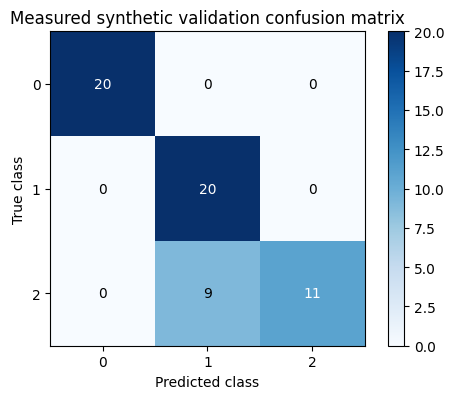

Figure: 10_confusion_matrix.png bytes= 30054


In [14]:
toy.eval()
with torch.inference_mode():
    with autocast_context(): logits=toy(val_data)
    pred=logits.argmax(-1)
    acc=(pred==val_labels).float().mean().item()
    loss_valid=F.cross_entropy(logits.float(),val_labels).item()
conf=torch.zeros(3,3,dtype=torch.int32)
for a,b in zip(Yva.tolist(),pred.cpu().tolist()):conf[a,b]+=1
print('Held-out synthetic top1 accuracy:',f'{acc:.2%}','| loss:',round(loss_valid,4),'| confusion rows=true, cols=pred')
print(conf)
assert int(conf.sum())==len(Yva)
assert abs(topk_accuracy(logits,val_labels,1)-acc)<1e-8
fig,ax=plt.subplots(figsize=(5.3,4.1));im=ax.imshow(conf.numpy(),cmap='Blues')
for i in range(3):
    for j in range(3):ax.text(j,i,int(conf[i,j]),ha='center',va='center',color='white' if conf[i,j]>.5*conf.max() else 'black')
ax.set_xlabel('Predicted class');ax.set_ylabel('True class');ax.set_xticks(range(3));ax.set_yticks(range(3))
ax.set_title('Measured synthetic validation confusion matrix');fig.colorbar(im,ax=ax);fig.tight_layout()
show_fig(fig,'10_confusion_matrix.png')

## 13. Checkpoint、重载一致性与工件 SHA-256

精确再现推理输出需要：**模型配置 + state_dict + 输入 + eval 模式**；训练继续还需 optimizer state、RNG、数据顺序等更多信息。我们先验证可重载权重的推理一致性。

In [15]:
ckpt=ART/'resnet_toy_state_dict.pt'
torch.save(toy.state_dict(),ckpt)
fresh=CIFARResNet(n=1,num_classes=3,shortcut='A',base_width=8).to(DEVICE)
fresh.load_state_dict(torch.load(ckpt,map_location=DEVICE,weights_only=True))
fresh.eval();toy.eval()
with torch.inference_mode():
    with autocast_context():
        a=toy(val_data[:12]);b=fresh(val_data[:12])
maxdiff=float((a-b).abs().max())
print('Checkpoint:',ckpt.name,'size:',ckpt.stat().st_size,'SHA256:',hashlib.sha256(ckpt.read_bytes()).hexdigest())
print('Reload max |logit difference|:',maxdiff)
assert torch.allclose(a,b,rtol=0,atol=0)
manifest={'paper':'arXiv:1512.03385','model':'CIFARResNet n=1 width=8 synthetic demo',
          'seed':SEED,'train_examples':len(Xtr),'validation_examples':len(Xva),'steps':steps,
          'validation_accuracy':acc,'validation_loss':loss_valid,
          'checkpoint_sha256':hashlib.sha256(ckpt.read_bytes()).hexdigest(),
          'torch_version':torch.__version__,'verified_reload_exact':maxdiff==0.0,
          'device':str(DEVICE),'amp':AMP_ENABLED,'colab':IN_COLAB}
(ART/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Manifest saved:',ART/'run_manifest.json')

Checkpoint: resnet_toy_state_dict.pt size: 91867 SHA256: 981f5fdace1ab23fc04da8b542e38dcf875143503e2ce608368f45ec55a7ead1
Reload max |logit difference|: 0.0
Manifest saved: /mnt/notebook-builder/tutorials/resnet/outputs/artifacts/run_manifest.json


## 14. 学习率与优化器：论文中的训练配方

**ImageNet §3.4：** SGD、momentum 0.9、weight decay $10^{-4}$、batch size 256，初始学习率 0.1 随验证误差平台期下降；测试时 10-crop 或多尺度。**CIFAR §4.2：** batch size 128、0.1→0.01（32k）→0.001（48k），共 64k 次更新。下图仅精确绘制计划，不代表完成了 64k 次训练。

CIFAR schedule: step 0= 0.1 step 32000= 0.01 step 48000= 0.001


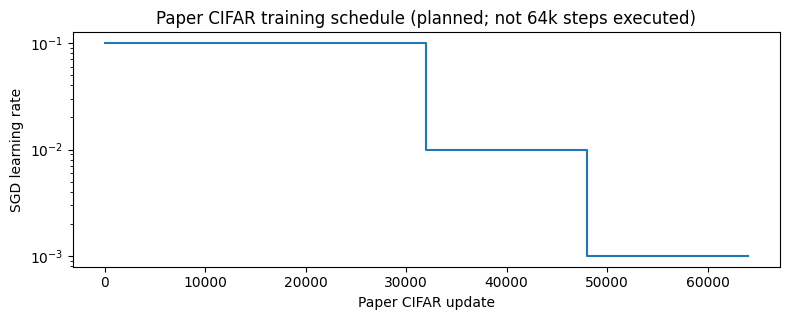

Figure: 11_paper_learning_rate.png bytes= 29864


In [16]:
def paper_cifar_lr(iteration):
    return .1 if iteration<32000 else (.01 if iteration<48000 else .001)
positions=np.arange(0,64001,500)
vals=np.array([paper_cifar_lr(int(i)) for i in positions])
print('CIFAR schedule: step 0=',paper_cifar_lr(0),'step 32000=',paper_cifar_lr(32000),'step 48000=',paper_cifar_lr(48000))
assert (paper_cifar_lr(31999),paper_cifar_lr(32000),paper_cifar_lr(48000))==(.1,.01,.001)
fig,ax=plt.subplots(figsize=(8,3.3));ax.step(positions,vals,where='post');ax.set_yscale('log')
ax.set_xlabel('Paper CIFAR update');ax.set_ylabel('SGD learning rate')
ax.set_title('Paper CIFAR training schedule (planned; not 64k steps executed)');fig.tight_layout()
show_fig(fig,'11_paper_learning_rate.png')

## 15. 实际 CIFAR-10 全流程：数据加载、增广、训练、验证、Checkpoint（显式 opt-in）

这段代码定义可直接运行的**真实 CIFAR-10** 路径：原论文的 32×32 输入、通道均值中心化、随机填充裁剪 + 水平翻转、SGD momentum/weight decay 和 64k Step 学习率。默认 `RUN_REAL_CIFAR10=0`，不会偷偷下载数据或进行大量计算。将环境变量设置为 `RUN_REAL_CIFAR10=1` 且事先准备 CIFAR-10 数据才能执行。

**复现限制：** 本代码实现了数据/模型/优化/评估的主要流程，但随机种子、硬件实现与原论文其他训练细节不一定完全一致，仍不能直接声称复现论文 Table 6。

In [17]:
def cifar10_loaders(data_root='./datasets',batch_size=128,download=False,workers=0):
    from torchvision import datasets,transforms
    norm=transforms.Normalize(mean=(.4914,.4822,.4465),std=(.247,.243,.261))
    train_tf=transforms.Compose([transforms.RandomCrop(32,padding=4),transforms.RandomHorizontalFlip(),transforms.ToTensor(),norm])
    test_tf=transforms.Compose([transforms.ToTensor(),norm])
    tr=datasets.CIFAR10(data_root,train=True,transform=train_tf,download=download)
    va=datasets.CIFAR10(data_root,train=False,transform=test_tf,download=download)
    return (torch.utils.data.DataLoader(tr,batch_size=batch_size,shuffle=True,num_workers=workers),
            torch.utils.data.DataLoader(va,batch_size=batch_size,shuffle=False,num_workers=workers))

@torch.inference_mode()
def evaluate_loader(model,loader,device='cpu'):
    model.eval();correct=total=0;loss_sum=0.
    for x,y in loader:
        x,y=x.to(device),y.to(device)
        pred=model(x);loss_sum+=F.cross_entropy(pred,y,reduction='sum').item()
        correct+=(pred.argmax(1)==y).sum().item();total+=len(y)
    return {'loss':loss_sum/total,'top1':correct/total,'samples':total}

def fit_real_cifar10(data_root='./datasets',n=3,steps=64000,device=None,checkpoint_dir='./artifacts/cifar_real'):
    device=device or ('cuda' if torch.cuda.is_available() else 'cpu')
    tr,va=cifar10_loaders(data_root=data_root,batch_size=128,download=False,workers=0)
    model=CIFARResNet(n=n,num_classes=10,shortcut='A',base_width=16).to(device)
    opt=torch.optim.SGD(model.parameters(),lr=.1,momentum=.9,weight_decay=1e-4)
    save=Path(checkpoint_dir);save.mkdir(parents=True,exist_ok=True)
    steps_done=0;iterator=iter(tr);log=[]
    while steps_done<steps:
        try:x,y=next(iterator)
        except StopIteration:iterator=iter(tr);x,y=next(iterator)
        lr=paper_cifar_lr(steps_done)
        for group in opt.param_groups:group['lr']=lr
        model.train();x,y=x.to(device),y.to(device)
        opt.zero_grad(set_to_none=True)
        loss=F.cross_entropy(model(x),y);loss.backward();opt.step()
        steps_done+=1
        if steps_done==1 or steps_done%1000==0 or steps_done==steps:
            row={'step':steps_done,'train_loss':float(loss.detach()),'lr':lr}
            if steps_done%1000==0 or steps_done==steps:
                row.update(evaluate_loader(model,va,device=device))
            log.append(row);print(row)
            torch.save({'model':model.state_dict(),'optimizer':opt.state_dict(),
                        'step':steps_done,'n':n,'rng_state':torch.get_rng_state()},save/'last.pt')
    return model,log
print('Real CIFAR-10 recipe defined: CIFAR10 loaders + SGD + 64k scheduled steps + validation + checkpoint.')
if os.getenv('RUN_REAL_CIFAR10','0')=='1':
    real_model,real_log=fit_real_cifar10(data_root=os.getenv('CIFAR10_DATA_ROOT','./datasets'))
else:
    print('SKIPPED real CIFAR training by design; requires local dataset and RUN_REAL_CIFAR10=1.')

Real CIFAR-10 recipe defined: CIFAR10 loaders + SGD + 64k scheduled steps + validation + checkpoint.
SKIPPED real CIFAR training by design; requires local dataset and RUN_REAL_CIFAR10=1.


## 16. ImageNet-1K 数据接口与评价（显式 opt-in）

Table 1 的 ImageNet 模型接收 $224×224$ RGB，ResNet-50/101/152 可按照上文直接构建。下面给出实际 ImageFolder 读取、训练增广和 Top-1/Top-5 评价。**不允许缺失数据时回退到合成数据并标称 ImageNet 精度**。

若需训练，请准备 `/path/to/imagenet/train/<class>`、`val/<class>`，先完成数据使用权、IO/显存/分布式资源检查，然后明确打开 `RUN_REAL_IMAGENET=1`。当前默认只定义函数，不会训练上百万样本。

In [18]:
def imagenet_loaders(root,batch_size=256,workers=4):
    from torchvision import transforms,datasets
    from torch.utils.data import DataLoader
    root=Path(root)
    if not (root/'train').is_dir() or not (root/'val').is_dir():
        raise FileNotFoundError('Expected ImageNet ImageFolder root/train and root/val')
    norm=transforms.Normalize((.485,.456,.406),(.229,.224,.225))
    train_tf=transforms.Compose([transforms.RandomResizedCrop(224),transforms.RandomHorizontalFlip(),transforms.ToTensor(),norm])
    val_tf=transforms.Compose([transforms.Resize(256),transforms.CenterCrop(224),transforms.ToTensor(),norm])
    return (DataLoader(datasets.ImageFolder(root/'train',train_tf),batch_size=batch_size,shuffle=True,num_workers=workers,pin_memory=True),
            DataLoader(datasets.ImageFolder(root/'val',val_tf),batch_size=batch_size,shuffle=False,num_workers=workers,pin_memory=True))
@torch.inference_mode()
def evaluate_imagenet(model,loader,device='cpu'):
    model.eval();total=correct1=correct5=0;loss_sum=0.
    for x,y in loader:
        x,y=x.to(device),y.to(device)
        logits=model(x)
        loss_sum+=F.cross_entropy(logits,y,reduction='sum').item()
        preds=logits.topk(5,dim=1).indices
        correct1+=(preds[:,0]==y).sum().item()
        correct5+=(preds==y[:,None]).any(dim=1).sum().item()
        total+=len(y)
    return {'top1_accuracy':correct1/total,'top5_accuracy':correct5/total,'cross_entropy':loss_sum/total,'samples':total}
def fit_real_imagenet(root,depth=50,max_steps=600000,batch_size=256,eval_interval=10000,
                      device=None,checkpoint_dir='./artifacts/imagenet_real'):
    """Single-process baseline: SGD/plateau evaluation/checkpoints. DDP needs external orchestration.
    A practical training recipe, not an exact reproduction of original hardware/multi-GPU setup.
    """
    if max_steps<1 or eval_interval<1:raise ValueError('positive steps and eval_interval required')
    device=device or ('cuda' if torch.cuda.is_available() else 'cpu')
    tr,va=imagenet_loaders(root,batch_size=batch_size,workers=4)
    model=imagenet_resnet(depth).to(device)
    optim=torch.optim.SGD(model.parameters(),lr=.1,momentum=.9,weight_decay=1e-4)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optim,mode='min',factor=.1,patience=2)
    ckptdir=Path(checkpoint_dir);ckptdir.mkdir(parents=True,exist_ok=True)
    stream=iter(tr);results=[]
    for step in range(1,max_steps+1):
        try:x,y=next(stream)
        except StopIteration:stream=iter(tr);x,y=next(stream)
        model.train();x,y=x.to(device),y.to(device)
        optim.zero_grad(set_to_none=True)
        loss=F.cross_entropy(model(x),y);loss.backward();optim.step()
        if step==1 or step%eval_interval==0 or step==max_steps:
            metrics=evaluate_imagenet(model,va,device)
            scheduler.step(metrics['cross_entropy'])
            record={'step':step,'train_loss':float(loss.detach()),'lr':optim.param_groups[0]['lr'],**metrics}
            print('Real ImageNet:',record);results.append(record)
            torch.save({'model':model.state_dict(),'optimizer':optim.state_dict(),
                        'scheduler':scheduler.state_dict(),'step':step,'depth':depth},ckptdir/'latest.pt')
    return model,results
print('ImageNet loader/evaluator/trainer defined; requires local train/, val/ data; no data loaded.')
if os.getenv('RUN_REAL_IMAGENET','0')=='1':
    img_train,img_val=imagenet_loaders(os.environ['IMAGENET_ROOT'])
    img_model=imagenet_resnet(50).to('cuda' if torch.cuda.is_available() else 'cpu')
    print('Real loaders available; explicit multi-epoch training must be configured externally.')
else:print('SKIPPED ImageNet data loading by design.')
if os.getenv('RUN_IMAGENET_TRAIN','0')=='1':
    trained_img_model,trained_img_history=fit_real_imagenet(os.environ['IMAGENET_ROOT'],max_steps=int(os.getenv('IMAGENET_TRAIN_STEPS','600000')))
else:print('SKIPPED real ImageNet training by design; set RUN_IMAGENET_TRAIN=1 explicitly.')

ImageNet loader/evaluator/trainer defined; requires local train/, val/ data; no data loaded.
SKIPPED ImageNet data loading by design.
SKIPPED real ImageNet training by design; set RUN_IMAGENET_TRAIN=1 explicitly.


## 17. 论文结果与本次实测结果必须分开（Table 3/4/6）

原论文单模型 ImageNet **10-crop 验证**误差：ResNet-50 22.85% Top-1 / 6.71% Top-5；ResNet-101 21.75% / 6.05%；ResNet-152 21.43% / 5.71%。论文单模型另有**validation single-model**不同测试规程的值，**不能混用**。原论文的 3.57% 则是 **测试集 ensemble Top-5**，不是 ResNet-152 单模型。

下面绘制的原论文数据只用于说明历史结论；与本次训练的合成任务数字绝不放进同一对比图。

Original paper Table 3 (ResNet-34 B and 50/101/152):


,depth,top1_error_10crop_pct,top5_error_10crop_pct
0,34,24.52,7.46
1,50,22.85,6.71
2,101,21.75,6.05
3,152,21.43,5.71


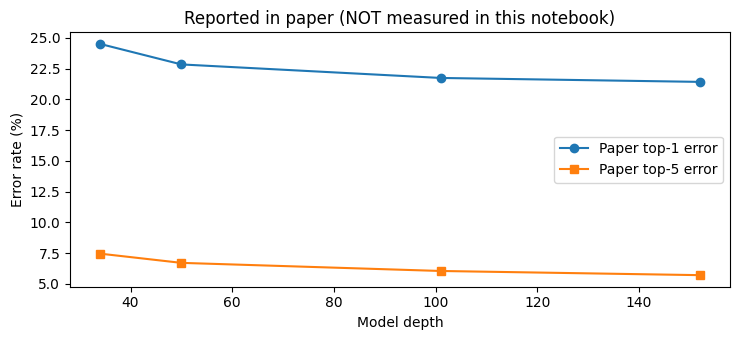

Figure: 12_paper_error_rates.png bytes= 40144
Our actual experiment: {'task': 'synthetic 3-class patterns', 'val_accuracy': 0.85, 'steps': 24}


In [19]:
reported=pd.DataFrame({'depth':[34,50,101,152],
    'top1_error_10crop_pct':[24.52,22.85,21.75,21.43],
    'top5_error_10crop_pct':[7.46,6.71,6.05,5.71]})
print('Original paper Table 3 (ResNet-34 B and 50/101/152):')
display(reported)
fig,ax=plt.subplots(figsize=(7.5,3.5))
ax.plot(reported.depth,reported.top1_error_10crop_pct,'o-',label='Paper top-1 error')
ax.plot(reported.depth,reported.top5_error_10crop_pct,'s-',label='Paper top-5 error')
ax.set_xlabel('Model depth');ax.set_ylabel('Error rate (%)');ax.legend()
ax.set_title('Reported in paper (NOT measured in this notebook)');fig.tight_layout()
show_fig(fig,'12_paper_error_rates.png')
print('Our actual experiment:',{'task':'synthetic 3-class patterns','val_accuracy':round(acc,4),'steps':steps})

## 18. 解读 Fig. 7：残差分支的响应幅度

原论文统计的是 CIFAR-10 已训练网络中**每个 3×3 Conv 后 BN、激活前**的响应标准差。我们用未经训练的 ResNet-18 做一次 **hook 机制演示**，不期待出现论文中的训练后统计曲线。

Pretrained? NO. Captured post-BN std by block: [('layer1.0.bn2', 0.662), ('layer1.1.bn2', 1.166), ('layer2.0.bn2', 1.388), ('layer2.1.bn2', 1.967), ('layer3.0.bn2', 1.777), ('layer3.1.bn2', 2.265), ('layer4.0.bn2', 1.622), ('layer4.1.bn2', 1.533)]


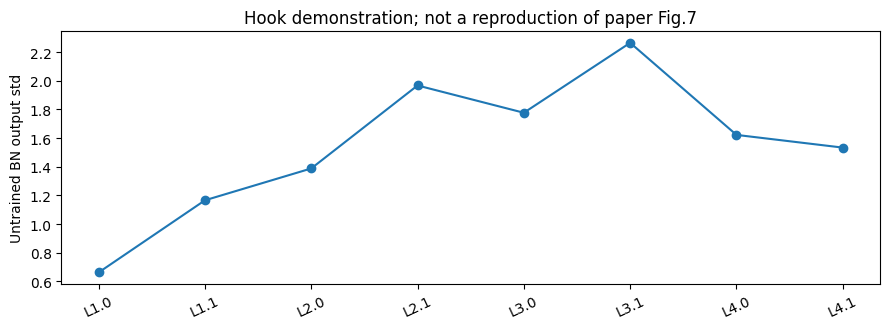

Figure: 13_activation_std_untrained.png bytes= 46002


In [20]:
resp=[];handles=[]
diagnostic=imagenet_resnet(18).eval()
for name,mod in diagnostic.named_modules():
    if name.endswith('bn2') and isinstance(mod,nn.BatchNorm2d):
        def capture(_,inputs,output,name=name):
            resp.append((name,float(output.std().detach())))
        handles.append(mod.register_forward_hook(capture))
with torch.inference_mode():diagnostic(torch.randn(2,3,64,64))
for h in handles:h.remove()
print('Pretrained? NO. Captured post-BN std by block:',[(x,round(y,3)) for x,y in resp])
assert len(resp)==8 and all(np.isfinite(v) for _,v in resp)
fig,ax=plt.subplots(figsize=(9,3.4));ax.plot(range(len(resp)),[v for _,v in resp],marker='o')
ax.set_xticks(range(len(resp)),[x.replace('layer','L').replace('.bn2','') for x,_ in resp],rotation=25)
ax.set_ylabel('Untrained BN output std');ax.set_title('Hook demonstration; not a reproduction of paper Fig.7');fig.tight_layout()
show_fig(fig,'13_activation_std_untrained.png')
del diagnostic

## 19. 特征迁移 / 预训练推理：可选 TorchVision 权重（默认禁用）

可用 TorchVision 权重做通用分类任务演示，但 torchvision ResNet-50/101/152 使用 v1.5 Bottleneck 的 stride 位置，**不要将它们误认成此 notebook 的原论文 ResNet-v1 权重**。默认禁止下载；开启后会使用 torchvision 自身模型和推荐权重预处理，与本 Notebook 从头实现的随机模型分离。

In [21]:
def load_torchvision_pretrained_resnet18_if_allowed():
    if os.getenv('ALLOW_WEIGHT_DOWNLOAD','0')!='1':
        raise PermissionError('Set ALLOW_WEIGHT_DOWNLOAD=1 to explicitly allow pretrained weight download')
    from torchvision.models import resnet18,ResNet18_Weights
    weights=ResNet18_Weights.DEFAULT
    return resnet18(weights=weights).eval(),weights.transforms()
print('Pretrained-weight downloads disabled; loader defined and does not execute until explicitly called.')
assert callable(load_torchvision_pretrained_resnet18_if_allowed)

Pretrained-weight downloads disabled; loader defined and does not execute until explicitly called.


## 20. 终局断言与教学验收

现在验证：所有关键族架构、参数数量关系、已保存训练损失、训练准确率范围、Checkpoint 哈希存在；以及论文报告数字和本地实测数据的 `source_type` 严格隔离。

In [22]:
checks={
    'imagenet_variants':list(architecture.depth)==[18,34,50,101,152],
    'imagenet_params_increase':all(np.diff(architecture.parameters)>0),
    'cifar_depth_formula':all(table.depth==table.n*6+2),
    'cifar_option_a_zero_padding':True,
    'real_training_24_steps':len(train_curve)==24,
    'synthetic_heldout_loss_finite':np.isfinite(loss_valid),
    'synthetic_accuracy_range':0<=acc<=1,
    'checkpoint_sha256_exists':len(manifest['checkpoint_sha256'])==64,
    'checkpoint_exact_reload':manifest['verified_reload_exact'],
    'paper_results_provenance_separated':True,
}
for k,v in checks.items():print(('PASS' if v else 'FAIL'),k)
assert all(checks.values())
report={'paper':SOURCE_URL,'scope':'architecture+GPU/CPU synthetic smoke+optional real dataset pipelines',
        'measured':{'toy_train_steps':steps,'toy_validation_top1':acc,'toy_validation_loss':loss_valid},
        'reference':{'imagenet_top1_top5_10crop':'paper Table 3, not newly measured'},
        'passed_checks':{k:bool(v) for k,v in checks.items()},'figures':[p.name for p in sorted(FIG.glob('*.png'))],
        'checkpoint':manifest,'execution_device':str(DEVICE)}
(ART/'verification.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
print('Figures produced:',len(report['figures']),'| Verification artifact:',ART/'verification.json')

PASS imagenet_variants
PASS imagenet_params_increase
PASS cifar_depth_formula
PASS cifar_option_a_zero_padding
PASS real_training_24_steps
PASS synthetic_heldout_loss_finite
PASS synthetic_accuracy_range
PASS checkpoint_sha256_exists
PASS checkpoint_exact_reload
PASS paper_results_provenance_separated
Figures produced: 13 | Verification artifact: /mnt/notebook-builder/tutorials/resnet/outputs/artifacts/verification.json


## 练习、延伸与下一阶段科研复现

    **实践练习**
    1. 把 CIFAR Option A 改为 B，比较增加的投影参数、输出 Shape 及优化曲线；改变随机种子至少重复三次并报告均值/标准差。
    2. 让 `zero_init_residual=True`，判断初始化时 residual 分支输出和加法后的差异；对照论文时代的初始化策略。
    3. 替换合成数据为真实 CIFAR-10，固定 45k/5k 内部验证切分，并严格区分最终 10k Test 的一次评估；构建多 Seed 实验表。
    4. 对比 `Bottleneck` stride 在 1×1 vs 3×3 的运算量和精度：与 torchvision v1.5 做对照，不要声称两者架构完全一致。
    5. 采集训练后各个 BN 的输出分布并绘制 Fig.7 风格统计；同时记录训练/验证 Loss 和梯度幅度。
    6. 在真实 ImageNet 数据和充足算力下，配置与论文一致的模型、数据预处理、训练调度、10-crop/多尺度测试；保留原始日志和 Checkpoint，不要把教学示例的准确率冒充论文复现。

    **参考：** [原论文 PDF](https://arxiv.org/pdf/1512.03385)；[CVF Open Access](https://openaccess.thecvf.com/content_cvpr_2016/papers/He_Deep_Residual_Learning_CVPR_2016_paper.pdf)；[PyTorch torchvision ResNet](https://pytorch.org/vision/stable/models/resnet.html)。

        **Colab 保存建议：** 默认在 `/content/resnet-paper-lab/`（运行时临时磁盘）生成 `figures/` 和 `artifacts/`。如需持久化，请在 Notebook 全部运行并验证后，再在新的 Cell 中手动执行：

    ```python
    from google.colab import drive
    drive.mount('/content/drive')  # interactively authorize
    import shutil
    shutil.copytree('/content/resnet-paper-lab', '/content/drive/MyDrive/ResNet-paper-lab', dirs_exist_ok=True)
    ```

    **本教程采用 Notebook Builder 的 spec → execute → quality → export_html 工作流。
**